# Recitation 3 | K-means and K-means++
Five houses sit at kilometer markers **0, 2, 6, 8, and 10**. If both cluster centers start at the same end of the road, how will the houses change groups as the centers move?

Replace the three TODO lines with your own code and answer the two short prompts. Run the cells in order as you go. [CS 461 lecture slides](https://firner.com/presentations/cs461/2026-Fall/cs461_23/#/)

In [1]:
import matplotlib.pyplot as plt

houses = [0, 2, 6, 8, 10]
start = (0, 2)

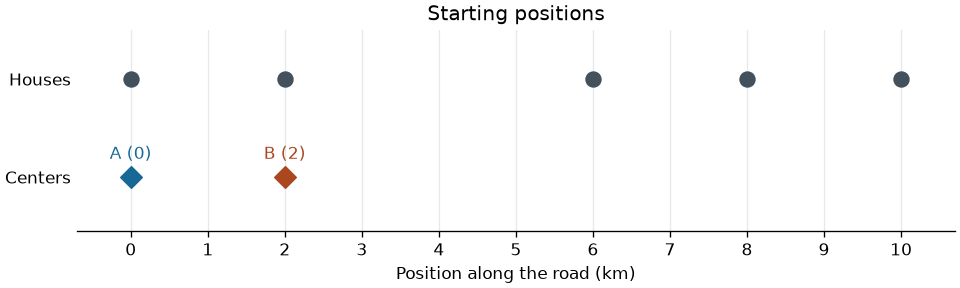

In [2]:
def plot_road(points, centers, title, groups=None):
    fig, ax = plt.subplots(figsize=(8, 2.4), layout="constrained")
    colors = ("#176797", "#AB471F")

    if groups is None:
        ax.scatter(points, [1] * len(points), s=78, color="#43515D")
    else:
        for group, color in zip(groups, colors):
            ax.scatter(group, [1] * len(group), s=78, color=color)

    for label, x, color in zip(("A", "B"), centers, colors):
        ax.scatter(x, 0, s=82, marker="D", color=color)
        ax.annotate(f"{label} ({x:g})", (x, 0), xytext=(0, 11),
                    textcoords="offset points", ha="center", color=color)

    ax.set(title=title, xlabel="Position along the road (km)",
           xlim=(min(points) - 0.7, max(points) + 0.7), ylim=(-0.55, 1.5),
           yticks=[0, 1], yticklabels=["Centers", "Houses"])
    ax.set_xticks(range(min(points), max(points) + 1))
    ax.grid(axis="x", color="#E5E9EB")
    ax.set_axisbelow(True)
    ax.spines[["top", "right", "left"]].set_visible(False)
    ax.tick_params(axis="y", length=0)
    plt.show()


plot_road(houses, start, "Starting positions")

## 1. Code one K-means round

**Assign.** Write `nearest(x, a, b)` to return group index `0` for center A or `1` for center B. Compare the distances using `abs`. Give ties to A.

**Update.** Write `mean_position(group)` to average the positions in one nonempty group. You can use `sum` and `len`. The loop below will use both functions in every round.

In [ ]:
def nearest(x, a, b):
    raise NotImplementedError("TODO 1: choose group 0 or 1")


def mean_position(group):
    raise NotImplementedError("TODO 2: return the mean position")

In [ ]:
# Check the rules on a different stretch of road.
assert nearest(11, 10, 20) == 0, "11 is closer to A."
assert nearest(18, 10, 20) == 1, "18 is closer to B."
assert nearest(15, 10, 20) == 0, "Give ties to A."
assert mean_position([1, 2, 6, 9]) == 4.5, "Include every house in the average."


def one_round(points, centers):
    a, b = centers
    groups = [[], []]
    for x in points:
        index = nearest(x, a, b)
        groups[index].append(x)
    if not all(groups):
        raise ValueError("A group is empty. Check your distance comparison.")
    updated = (mean_position(groups[0]), mean_position(groups[1]))
    return groups, updated


groups, updated = one_round(houses, start)
print(f"Round 1: A = {groups[0]}, B = {groups[1]}, updated centers = {updated}")

## 2. Predict a move, then run to convergence

**Before running the loop**, use the updated centers from round 1. Which house will switch groups in round 2? Give its distances to both centers.

**My prediction.** _Write one sentence here._

In [ ]:
def run_kmeans(points, centers):
    for step in range(1, 11):
        groups, updated = one_round(points, centers)
        print(f"{step}. Start {centers} | A {groups[0]}, B {groups[1]} | End {updated}")
        if updated == centers:
            return step, groups, updated
        centers = updated
    raise RuntimeError("Centers still moved after 10 rounds. Check your functions.")


baseline_rounds, final_groups, final_centers = run_kmeans(houses, start)

In [ ]:
plot_road(houses, final_centers, "Final K-means groups", groups=final_groups)

## 3. Change how the centers start

Keep the first center fixed at **0** so we can compare runs. K-means++ normally picks that first center uniformly at random. It samples the second center from the houses, giving each house a weight equal to its **squared distance** from the first center.

Write `seed_weight(x, first)`. For example, a house three units from the first center has weight 9. The code below uses your weights to draw a second center and runs your K-means functions again. The fixed random seed makes the draw repeatable.

In [ ]:
def seed_weight(x, first):
    raise NotImplementedError("TODO 3: return the squared distance")

In [ ]:
from random import Random

assert seed_weight(4, 7) == 9 and seed_weight(7, 7) == 0, "Check the squared distance."
first = start[0]
weights = [seed_weight(x, first) for x in houses]
total = sum(weights)
for x, weight in zip(houses, weights):
    print(f"House {x:2} | weight {weight:3} | chance {weight / total:.1%}")

second = Random(1).choices(houses, weights=weights, k=1)[0]
print(f"Sampled second center: {second}")
seeded_rounds, _, _ = run_kmeans(houses, (first, second))
print(f"Rounds including the final stability check: original {baseline_rounds}, K-means++ {seeded_rounds}")

**Explain the experiment.** Which house had the highest chance of being picked second, and why could the draw pick another house? Compare the two traces. How many rounds did each take, and how can you tell when to stop?

_Write two or three sentences here._